# 01 – Synthetic CubeSat telemetry and preprocessing

This notebook builds the dataset used in the rest of the project:

1. generate multivariate LEO CubeSat telemetry (95-min orbit, 35-min eclipse, 1 sample / 10 s),
2. inject **labelled** anomalies (point, contextual, collective),
3. preprocess: temporal split → z-score fitted on *nominal training* data → forward-fill + missingness mask → orbital encoding → sliding windows of length 512.

All reusable code lives in `src/data.py`; this notebook only calls it and checks the results.

**Setup.** Enable autoreload (edits to `src/*.py` are picked up without restarting the kernel) and put the project root on `sys.path`.
*Expected output:* the project root path and the torch / numpy versions.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import torch
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10, "font.size": 9})

print("project root:", ROOT)
print("torch", torch.__version__, "| numpy", np.__version__)

project root: D:\Project\Development\Mamba_CubeSat
torch 2.15.0+cpu | numpy 2.4.6


## 1. Configuration and seed
Fix all random seeds, then create the telemetry config. The derived quantities are checked with `assert`s:
95 min × 60 / 10 s = **570 samples per orbit**, 35 min → **210 eclipse samples**.
*Expected output:* the config, and `n_samples = 72 × 570 = 41040`.

In [2]:
from src import data
from src.train import set_seed

SEED = 0
set_seed(SEED)

cfg = data.TelemetryConfig(seed=SEED)
print(cfg)
print("samples/orbit:", cfg.samples_per_orbit, "| eclipse samples:", cfg.eclipse_samples,
      "| total samples:", cfg.n_samples, f"(= {cfg.n_samples * cfg.dt_s / 86400:.2f} days)")
assert cfg.samples_per_orbit == 570
assert cfg.eclipse_samples == 210

TelemetryConfig(dt_s=10.0, period_min=95.0, eclipse_min=35.0, n_orbits=72, seed=0, n_spikes=40, n_contextual=16, event_split_probs=(0.2, 0.3, 0.5), fade_orbits=4.0, fade_final_capacity=0.45, p_point_missing=0.002, n_comm_dropouts=60, split_fracs=(0.6, 0.2, 0.2))
samples/orbit: 570 | eclipse samples: 210 | total samples: 41040 (= 4.75 days)


## 2. Orbital phase and eclipse
`orbital_phase` returns time `t`, true anomaly ν ∈ [0, 2π) and the eclipse flag (eclipse centred on ν = π).
*Expected output:* the eclipse fraction ≈ 35/95 = 0.368, and ~210 eclipse samples per orbit.

In [3]:
t, nu, eclipse = data.orbital_phase(cfg)
print("t:", t.shape, "nu:", nu.shape, "eclipse:", eclipse.shape)
print(f"eclipse fraction: {eclipse.mean():.3f}   (expected {35/95:.3f})")
per_orbit = eclipse[: cfg.samples_per_orbit].sum()
print("eclipse samples in orbit 0:", per_orbit)
assert abs(eclipse.mean() - 35 / 95) < 0.01
assert nu.min() >= 0 and nu.max() < 2 * np.pi

t: (41040,) nu: (41040,) eclipse: (41040,)
eclipse fraction: 0.369   (expected 0.368)
eclipse samples in orbit 0: 209.0


## 3. Generate telemetry with anomalies
Channels: battery voltage, solar current (exactly 0 in eclipse), temperature (lagged sinusoid), 3 ADCS angular rates, RSSI (with dropouts → NaN).

Anomalies:
* **point** – 1–2 sample spikes of 5–9 σ on a random channel,
* **contextual** – a *normal* value in the *wrong* orbital phase (sunlit-level solar current, or warm temperature, during eclipse),
* **collective** – slow battery capacity fade over the last 4 orbits (deeper discharge, higher internal resistance).

*Expected output:* array shapes `(41040, 7)`, the labelled fraction, and the number of NaNs.

In [4]:
raw = data.generate_telemetry(cfg)
sig = raw["signals"]
print("signals:", sig.shape, "| channels:", raw["names"])
print("labels:", raw["labels"].shape, f"| anomalous fraction: {raw['labels'].mean():.3%}")
print("NaNs (missing):", int(np.isnan(sig).sum()))
print("events:", len(raw["events"]))

assert sig.shape == (cfg.n_samples, 7)
# physics check: on nominal, observed eclipse samples the solar current must be exactly 0
ecl_nom = (raw["eclipse"] == 1) & (raw["labels"] == 0) & ~np.isnan(sig[:, 1])
assert np.all(sig[ecl_nom, 1] == 0.0), "solar current should be 0 in eclipse"
print("OK: solar current is 0 on all nominal eclipse samples")

signals: (41040, 7) | channels: ['batt_voltage', 'solar_current', 'temperature', 'omega_x', 'omega_y', 'omega_z', 'rssi']
labels: (41040,) | anomalous fraction: 6.830%
NaNs (missing): 1688
events: 57
OK: solar current is 0 on all nominal eclipse samples


## 4. Anomaly inventory per split
Tabulate the injected events by type and by the split they fall into (the split is defined in section 7; we compute it here already to see the distribution).
*Expected output:* a table — point and contextual events spread over all splits, the single collective event at the end of **test**.

In [5]:
import pandas as pd

splits = data.temporal_split(cfg.n_samples, cfg.split_fracs)
def which_split(i):
    return next(k for k, sl in splits.items() if sl.start <= i < sl.stop)

ev = pd.DataFrame(raw["events"])
ev["length"] = ev["end"] - ev["start"]
ev["split"] = ev["start"].map(which_split)
display(pd.crosstab(ev["kind"], ev["split"], margins=True))
display(ev.groupby("kind")["length"].describe()[["count", "min", "max", "mean"]])

split,test,train,val,All
kind,,,,
collective,1,0,0,1
contextual,6,5,5,16
point,22,7,11,40
All,29,12,16,57


,count,min,max,mean
kind,,,,
collective,1.0,2280.0,2280.0,2280.0000
contextual,16.0,21.0,42.0,28.9375
point,40.0,1.0,2.0,1.5000


## 5. Missing data
Missing values are *not* anomalies: isolated packet losses on every channel (~0.2 %) and longer RSSI dropouts.
*Expected output:* ~0.2 % missing for most channels and a few % for `rssi`.

In [6]:
miss_frac = np.isnan(sig).mean(0)
for name, f in zip(raw["names"], miss_frac):
    print(f"{name:14s} {f:7.3%}")
assert miss_frac[6] > miss_frac[:6].max(), "RSSI should have the most missing data"

batt_voltage    0.192%
solar_current   0.168%
temperature     0.188%
omega_x         0.210%
omega_y         0.217%
omega_z         0.219%
rssi            2.919%


## 6. Plot a few orbits with anomalies
Small multiples, one axis per channel. Grey = eclipse, red = labelled anomaly.
We centre the view on the first contextual event.
*Expected output:* periodic signals; solar current drops to 0 in every grey band **except** where a red contextual event is; gaps in RSSI are dropouts.

first contextual event: {'id': 40, 'kind': 'contextual', 'start': 24799, 'end': 24820, 'channel': 'solar_current'}


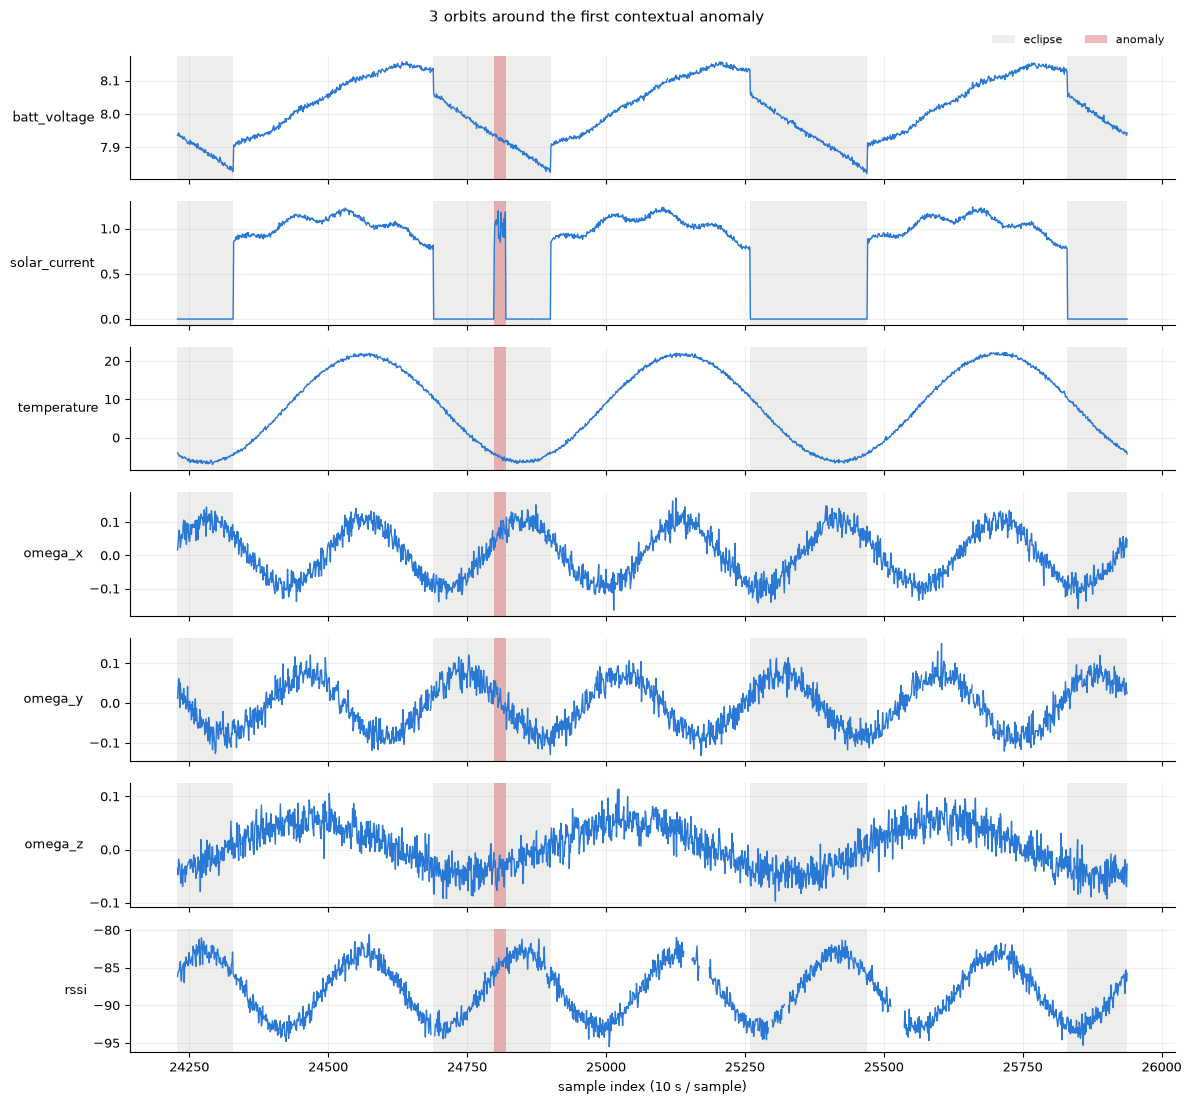

In [7]:
first_ctx = next(e for e in raw["events"] if e["kind"] == "contextual")
start = max(0, first_ctx["start"] - cfg.samples_per_orbit)
print("first contextual event:", first_ctx)
fig = data.plot_telemetry(raw, start=start, n_orbits=3,
                          title="3 orbits around the first contextual anomaly")
plt.show()

Zoom on a few point spikes (one channel each).
*Expected output:* isolated red spikes far outside the normal range.

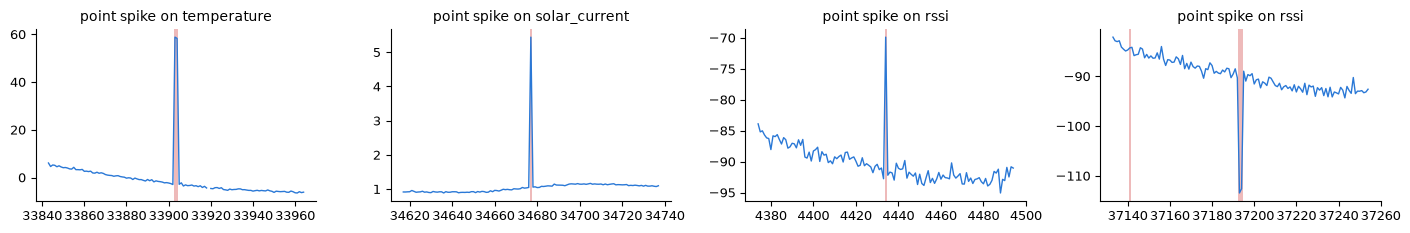

In [8]:
pts = [e for e in raw["events"] if e["kind"] == "point"][:4]
fig, axes = plt.subplots(1, len(pts), figsize=(14, 2.4))
for ax, e in zip(axes, pts):
    c = raw["names"].index(e["channel"])
    sl = slice(e["start"] - 60, e["end"] + 60)
    x = np.arange(sl.start, sl.stop)
    ax.plot(x, sig[sl, c], color=data.SERIES_COLOR, lw=1)
    data.shade_spans(ax, raw["labels"][sl], data.ANOM_COLOR, 0.35, x0=sl.start)
    ax.set_title(f"point spike on {e['channel']}")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

## 6b. Collective anomaly – battery capacity fade
Compare battery voltage in the last 8 orbits with the relative capacity. The fade starts 4 orbits before the end.
*Expected output:* eclipse voltage minima become progressively lower once capacity falls below 1.

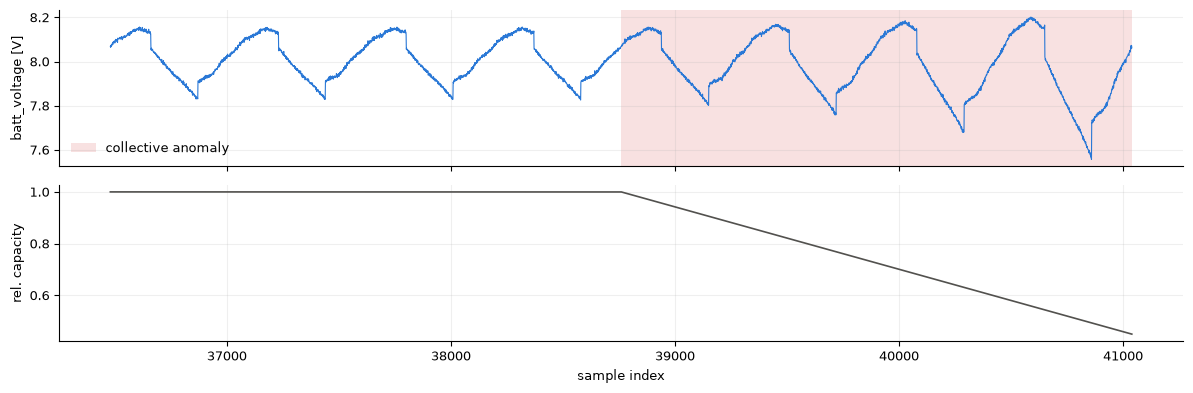

min nominal voltage before fade: 7.821 V | in last orbit: 7.557 V


In [9]:
spo = cfg.samples_per_orbit
sl = slice(cfg.n_samples - 8 * spo, cfg.n_samples)
x = np.arange(sl.start, sl.stop)
fig, axes = plt.subplots(2, 1, figsize=(12, 4), sharex=True)
axes[0].plot(x, sig[sl, 0], color=data.SERIES_COLOR, lw=0.8)
data.shade_spans(axes[0], raw["labels"][sl] * (raw["event_id"][sl] == len(raw["events"]) - 1),
                 data.ANOM_COLOR, 0.15, "collective anomaly", x0=sl.start)
axes[0].set_ylabel("batt_voltage [V]"); axes[0].legend(frameon=False, loc="lower left")
axes[1].plot(x, raw["capacity"][sl], color="#52514e", lw=1.2)
axes[1].set_ylabel("rel. capacity"); axes[1].set_xlabel("sample index")
for ax in axes: ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.2)
fig.tight_layout(); plt.show()

pre = slice(0, cfg.n_samples - 4 * spo)
v_nominal = np.where(raw["labels"][pre] == 0, sig[pre, 0], np.nan)   # exclude spikes
nominal_min = np.nanmin(v_nominal)
faded_min = np.nanmin(sig[-spo:, 0])
print(f"min nominal voltage before fade: {nominal_min:.3f} V | in last orbit: {faded_min:.3f} V")
assert faded_min < nominal_min

## 7. Preprocessing
`preprocess` does, in order:
1. **temporal split** 60/20/20 (contiguous blocks, no shuffling → no future leakage),
2. **z-score** per channel fitted only on *nominal* samples of the *training* split,
3. **forward-fill** NaNs (per split) + a **0/1 missingness mask** per signal (1 = was missing),
4. append **orbital encoding** `sin ν, cos ν, eclipse`.

Model input `X` therefore has 7 signals + 7 masks + 3 orbital = **17 channels**; the target `Y` has the 7 signals.
*Expected output:* split sizes 24624 / 8208 / 8208 and shapes `X (T, 17)`, `Y (T, 7)`, `M (T, 7)`.

In [10]:
proc = data.preprocess(raw)
print("input channels:", proc["input_names"])
for name in ("train", "val", "test"):
    s = proc[name]
    print(f"{name:5s} X {s['X'].shape}  Y {s['Y'].shape}  M {s['M'].shape}  "
          f"anomalous {s['labels'].mean():6.2%}")

sl = proc["splits"]
assert sl["train"].stop == sl["val"].start and sl["val"].stop == sl["test"].start
assert proc["train"]["X"].shape[1] == 17
assert sum(len(proc[k]["X"]) for k in ("train", "val", "test")) == cfg.n_samples

input channels: ['batt_voltage', 'solar_current', 'temperature', 'omega_x', 'omega_y', 'omega_z', 'rssi', 'miss_batt_voltage', 'miss_solar_current', 'miss_temperature', 'miss_omega_x', 'miss_omega_y', 'miss_omega_z', 'miss_rssi', 'sin_nu', 'cos_nu', 'eclipse']
train X (24624, 17)  Y (24624, 7)  M (24624, 7)  anomalous  0.58%
val   X (8208, 17)  Y (8208, 7)  M (8208, 7)  anomalous  2.05%
test  X (8208, 17)  Y (8208, 7)  M (8208, 7)  anomalous 30.36%


## 8. Check the z-score
On **nominal, observed training** samples every channel should have mean ≈ 0 and std ≈ 1. Val/test are only *transformed* with the training statistics, so they deviate a little (and the test split contains the fade).
*Expected output:* train mean ≈ 0.000, std ≈ 1.000; val/test close but not exact.

In [11]:
tr = proc["train"]
obs_nom = (tr["M"] == 0) & (tr["labels"][:, None] == 0)
for name in ("train", "val", "test"):
    s = proc[name]
    ok = (s["M"] == 0) & (s["labels"][:, None] == 0)
    mu = np.array([s["Y"][ok[:, c], c].mean() for c in range(7)])
    sd = np.array([s["Y"][ok[:, c], c].std() for c in range(7)])
    print(f"{name:5s} mean {np.round(mu, 3)}\n      std  {np.round(sd, 3)}")
mu_tr = np.array([tr["Y"][obs_nom[:, c], c].mean() for c in range(7)])
sd_tr = np.array([tr["Y"][obs_nom[:, c], c].std() for c in range(7)])
assert np.allclose(mu_tr, 0, atol=1e-3) and np.allclose(sd_tr, 1, atol=1e-3)
print("scaler mean (physical units):", np.round(proc["scaler"].mean, 3))

train mean [-0. -0.  0. -0.  0.  0. -0.]
      std  [1. 1. 1. 1. 1. 1. 1.]
val   mean [ 0.003 -0.009  0.004 -0.018  0.015  0.073 -0.031]
      std  [0.99  1.    0.99  0.991 0.998 0.999 0.991]
test  mean [-0.016  0.044  0.022  0.044 -0.088  0.301 -0.01 ]
      std  [0.998 0.986 0.994 1.002 1.011 0.989 1.002]
scaler mean (physical units): [ 8.0120e+00  6.5300e-01  8.1380e+00  5.0000e-03 -6.0000e-03 -0.0000e+00
 -8.8018e+01]


## 9. Forward-fill + missingness mask
Look at an RSSI dropout in the training split: the raw (z-scored) series has NaNs, the filled series holds the last value, and the mask is 1 exactly where data were missing.
*Expected output:* a flat segment in the filled series aligned with the mask = 1 region.

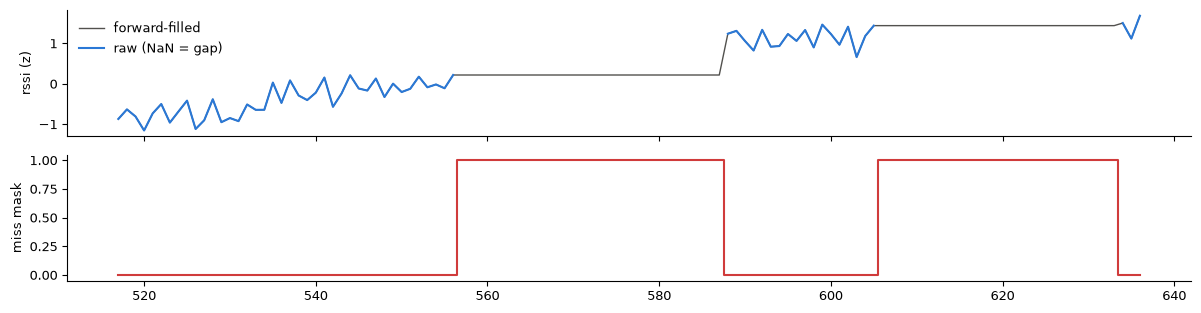

RSSI missing in train: 2.16%; mask matches NaN positions: OK


In [12]:
z_rssi = proc["scaler"].transform(sig[sl["train"]])[:, 6]
m = tr["M"][:, 6]
first_gap = int(np.argmax(np.convolve(m, np.ones(5), "valid") == 5))  # first gap >= 5 samples
w = slice(max(0, first_gap - 40), first_gap + 80)
x = np.arange(w.start, w.stop)
fig, axes = plt.subplots(2, 1, figsize=(12, 3.2), sharex=True)
axes[0].plot(x, tr["Y"][w, 6], color="#52514e", lw=1, label="forward-filled")
axes[0].plot(x, z_rssi[w], color=data.SERIES_COLOR, lw=1.5, label="raw (NaN = gap)")
axes[0].legend(frameon=False); axes[0].set_ylabel("rssi (z)")
axes[1].step(x, m[w], where="mid", color=data.ANOM_COLOR); axes[1].set_ylabel("miss mask")
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

nan_pos = np.isnan(z_rssi)
assert np.array_equal(nan_pos, m.astype(bool)), "mask must be 1 exactly at NaNs"
assert not np.isnan(tr["Y"]).any()
print(f"RSSI missing in train: {m.mean():.2%}; mask matches NaN positions: OK")

## 10. Orbital encoding
`sin ν`, `cos ν` give a continuous phase (no jump at 2π); the eclipse flag is binary. These channels let the model know *where in the orbit* it is, which is exactly what is needed to detect contextual anomalies.
*Expected output:* one sine, one cosine and a box-shaped eclipse flag per orbit; `sin² + cos² = 1`.

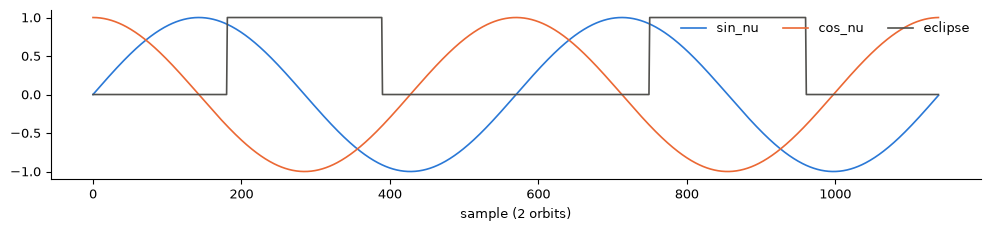

In [13]:
orb = tr["X"][: 2 * cfg.samples_per_orbit, 14:17]
fig, ax = plt.subplots(figsize=(12, 2.2))
for i, (name, col) in enumerate(zip(data.ORBIT_FEATURES, ["#2a78d6", "#eb6834", "#52514e"])):
    ax.plot(orb[:, i], label=name, color=col, lw=1.2)
ax.legend(frameon=False, ncol=3, loc="upper right"); ax.set_xlabel("sample (2 orbits)")
ax.spines[["top", "right"]].set_visible(False); plt.show()
assert np.allclose(orb[:, 0] ** 2 + orb[:, 1] ** 2, 1.0, atol=1e-5)
assert set(np.unique(orb[:, 2])) <= {0.0, 1.0}

## 11. Sliding windows (length 512)
Training uses **nominal windows only**: any window touching a labelled anomaly is dropped. Train stride = 64, validation stride = 128.
*Expected output:* window tensors `(W, 512, 17)` / `(W, 512, 7)`, the number of dropped windows, and 0 anomalous points inside the kept windows.

In [14]:
WINDOW = 512
all_tr = data.make_windows(tr, WINDOW, stride=64, nominal_only=False)
nom_tr = data.make_windows(tr, WINDOW, stride=64, nominal_only=True)
nom_va = data.make_windows(proc["val"], WINDOW, stride=128, nominal_only=True)
print("train windows: all", all_tr["X"].shape[0], "-> nominal", nom_tr["X"].shape[0])
print("  X", nom_tr["X"].shape, "Y", nom_tr["Y"].shape, "M", nom_tr["M"].shape)
print("val nominal windows:", nom_va["X"].shape)

assert nom_tr["X"].shape[1:] == (WINDOW, 17) and nom_tr["Y"].shape[1:] == (WINDOW, 7)
assert nom_tr["labels"].sum() == 0 and nom_va["labels"].sum() == 0
# window content must equal the underlying series
s0 = nom_tr["start"][3]
assert np.array_equal(nom_tr["X"][3], tr["X"][s0:s0 + WINDOW])

train windows: all 377 -> nominal 282
  X (282, 512, 17) Y (282, 512, 7) M (282, 512, 7)
val nominal windows: (21, 512, 17)


## 12. Look at one model input window
Heat-map of all 17 input channels of one training window (rows = channels).
*Expected output:* smooth periodic rows for the signals, mostly-zero mask rows with a few bright ticks, and the orbital rows at the bottom.

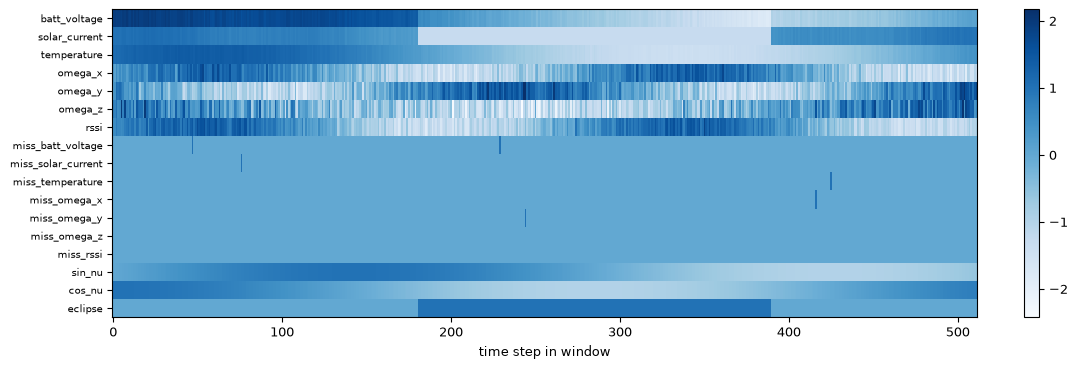

In [15]:
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(nom_tr["X"][0].T, aspect="auto", cmap="Blues", interpolation="nearest")
ax.set_yticks(range(17)); ax.set_yticklabels(proc["input_names"], fontsize=7)
ax.set_xlabel("time step in window"); fig.colorbar(im, ax=ax, fraction=0.02)
plt.show()

## 13. One-call version
`data.build_dataset()` runs everything above in one call; notebook 03 uses it. Because all randomness is seeded, it must reproduce the exact same arrays.
*Expected output:* `identical: True`.

In [16]:
raw2, proc2 = data.build_dataset(data.TelemetryConfig(seed=SEED))
same = np.array_equal(proc2["train"]["X"], proc["train"]["X"]) and \
       np.array_equal(proc2["train_windows"]["X"], nom_tr["X"])
print("identical:", same)
assert same

identical: True


## Summary
* 72 orbits (~4.75 days) of 7-channel telemetry, 57 labelled events (40 point, 16 contextual, 1 collective); events are placed 20/30/50 % in train/val/test so the test set has enough events for event-wise metrics.
* Inputs: 17 channels (7 z-scored signals, 7 missingness masks, 3 orbital features); targets: 7 signals.
* The z-score uses nominal training statistics only, so validation/test anomalies never leak into normalisation.
* Next: `02_mamba_block.ipynb` builds and tests the Mamba model.